# Fake News Classification using a BERT Transformer (LIAR Dataset)
**Student:** Anwesha Mahesh Mulge  |  **Registration No.:** 23FE10ITE00008  |  **Roll No.:** 65
**Assigned case study:** Case Study 13 – Fake News Classification (Architecture: BERT Transformer)

Pipeline: load LIAR -> map 6 truthfulness labels to binary -> tokenize -> fine-tune `bert-base-uncased`
-> evaluate on held-out test set -> compare with majority-class and TF-IDF + Logistic Regression baselines.

In [1]:
import os, json, time, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
DATA_DIR, OUT_DIR = "data", "outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("Device:", DEVICE, "| torch", torch.__version__)

/Users/anweshamulge/Downloads/FakeNews_BERT_23FE10ITE00008/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps | torch 2.15.0


## 1. Dataset loading
LIAR (Wang, 2017): 12.8k short political statements from PolitiFact with six truthfulness labels and
speaker metadata. Official train / valid / test splits are used as provided.
Download: https://www.cs.ucsb.edu/~william/data/liar_dataset.zip

In [2]:
COLS = ["id", "label", "statement", "subject", "speaker", "job", "state", "party",
        "barely_true_c", "false_c", "half_true_c", "mostly_true_c", "pants_fire_c", "context"]
def load(split):
    return pd.read_csv(f"{DATA_DIR}/{split}.tsv", sep="\t", header=None, names=COLS, quoting=3)
train_df, val_df, test_df = load("train"), load("valid"), load("test")
print({k: len(v) for k, v in [("train", train_df), ("valid", val_df), ("test", test_df)]})
train_df.head(3)

{'train': 10269, 'valid': 1284, 'test': 1283}


,id,label,statement,subject,speaker,job,state,party,barely_true_c,false_c,half_true_c,mostly_true_c,pants_fire_c,context
0,2635.json,false,Says the Annies List political group supports ...,abortion,dwayne-bohac,State representative,Texas,republican,0,1,0,0,0,a mailer
1,10540.json,half-true,When did the decline of coal start? It started...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0,0,1,1,0,a floor speech.
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by vo...",foreign-policy,barack-obama,President,Illinois,democrat,70,71,160,163,9,Denver


## 2. Label mapping and class balance
Six-way labels are mapped to a binary task:
* **Fake (0)**: `pants-fire`, `false`, `barely-true`
* **Real (1)**: `half-true`, `mostly-true`, `true`

/var/folders/5t/kz_8mtk54ll_xl1h7sd679ww0000gn/T/ipykernel_1745/1711243585.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="label", data=train_df, order=order, ax=ax[0], palette="RdYlGn"); ax[0].set_title("Original 6-way labels (train)")
/var/folders/5t/kz_8mtk54ll_xl1h7sd679ww0000gn/T/ipykernel_1745/1711243585.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=train_df["y"].map(dict(enumerate(CLASS_NAMES))), order=CLASS_NAMES, ax=ax[1], palette=["#d9534f", "#5cb85c"])


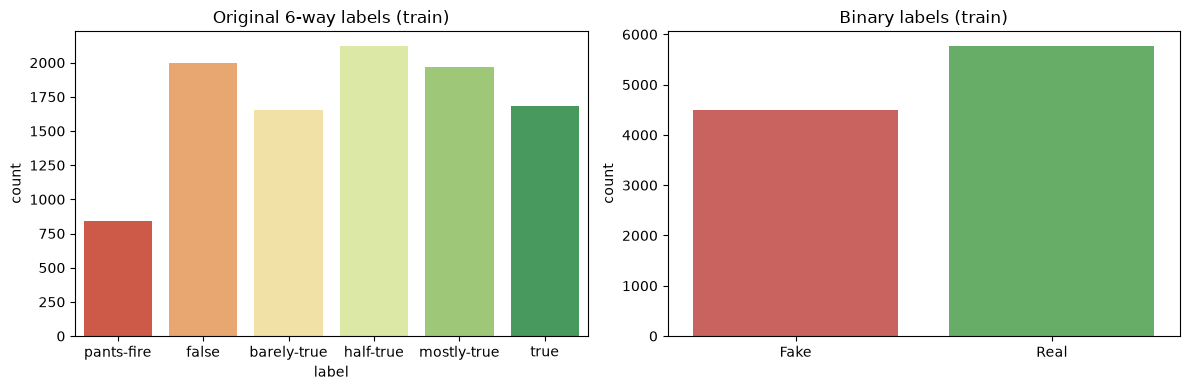

train {1: 0.562, 0: 0.438}
valid {1: 0.52, 0: 0.48}
test {1: 0.567, 0: 0.433}


In [3]:
LABEL_MAP = {"pants-fire": 0, "false": 0, "barely-true": 0, "half-true": 1, "mostly-true": 1, "true": 1}
CLASS_NAMES = ["Fake", "Real"]
for d in (train_df, val_df, test_df):
    d["y"] = d["label"].map(LABEL_MAP)
order = ["pants-fire", "false", "barely-true", "half-true", "mostly-true", "true"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="label", data=train_df, order=order, ax=ax[0], palette="RdYlGn"); ax[0].set_title("Original 6-way labels (train)")
sns.countplot(x=train_df["y"].map(dict(enumerate(CLASS_NAMES))), order=CLASS_NAMES, ax=ax[1], palette=["#d9534f", "#5cb85c"])
ax[1].set_title("Binary labels (train)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/class_distribution.png", dpi=150); plt.show()
for n, d in [("train", train_df), ("valid", val_df), ("test", test_df)]:
    print(n, d["y"].value_counts(normalize=True).round(3).to_dict())

## 3. Preprocessing
The statement is the primary input. Short metadata (subject, speaker, party, context) is appended as
extra text so BERT can use it; missing fields become "unknown". Text is lower-cased by the uncased
WordPiece tokenizer, truncated/padded to 96 tokens.

In [4]:
def build_text(d):
    f = lambda c: d[c].fillna("unknown").astype(str)
    return (f("statement") + " [SEP] subject: " + f("subject") + " ; speaker: " + f("speaker")
            + " ; party: " + f("party") + " ; context: " + f("context"))
for d in (train_df, val_df, test_df):
    d["text"] = build_text(d)
print(train_df["text"].iloc[0])

MODEL_NAME, MAX_LEN, BATCH, EPOCHS, LR = "bert-base-uncased", 96, 16, 3, 2e-5
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
lens = [len(tokenizer.tokenize(t)) for t in train_df["text"].sample(2000, random_state=SEED)]
print(f"Token length: mean={np.mean(lens):.1f}, 95th pct={np.percentile(lens,95):.0f}, max={max(lens)}")

class LiarDS(Dataset):
    def __init__(self, df):
        self.enc = tokenizer(list(df["text"]), truncation=True, padding="max_length", max_length=MAX_LEN, return_tensors="pt")
        self.y = torch.tensor(df["y"].values)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return {k: v[i] for k, v in self.enc.items()}, self.y[i]

train_dl = DataLoader(LiarDS(train_df), batch_size=BATCH, shuffle=True)
val_dl = DataLoader(LiarDS(val_df), batch_size=64)
test_dl = DataLoader(LiarDS(test_df), batch_size=64)

Says the Annies List political group supports third-trimester abortions on demand. [SEP] subject: abortion ; speaker: dwayne-bohac ; party: republican ; context: a mailer


Token length: mean=49.7, 95th pct=70, max=120


## 4. Model: BERT-base + classification head
`[CLS]`-token representation from 12 Transformer encoder layers (768 hidden, 12 heads, ~110M params)
-> dropout (0.1) -> linear layer (768 -> 2) -> softmax. All layers are fine-tuned with AdamW.

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(DEVICE)
n_total = sum(p.numel() for p in model.parameters()); n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model.classifier, model.bert.embeddings, sep="\n")
print(f"Encoder layers: {model.config.num_hidden_layers}, hidden: {model.config.hidden_size}, heads: {model.config.num_attention_heads}")
print(f"Total parameters: {n_total:,} | Trainable: {n_train:,}")

W1104 20:46:41.305000 1745 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 5227.09it/s]


[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=2, bias=True)
BertEmbeddings(
  (word_embeddings): Embedding(30522, 768, padding_idx=0)
  (position_embeddings): Embedding(512, 768)
  (token_type_embeddings): Embedding(2, 768)
  (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
)
Encoder layers: 12, hidden: 768, heads: 12
Total parameters: 109,483,778 | Trainable: 109,483,778


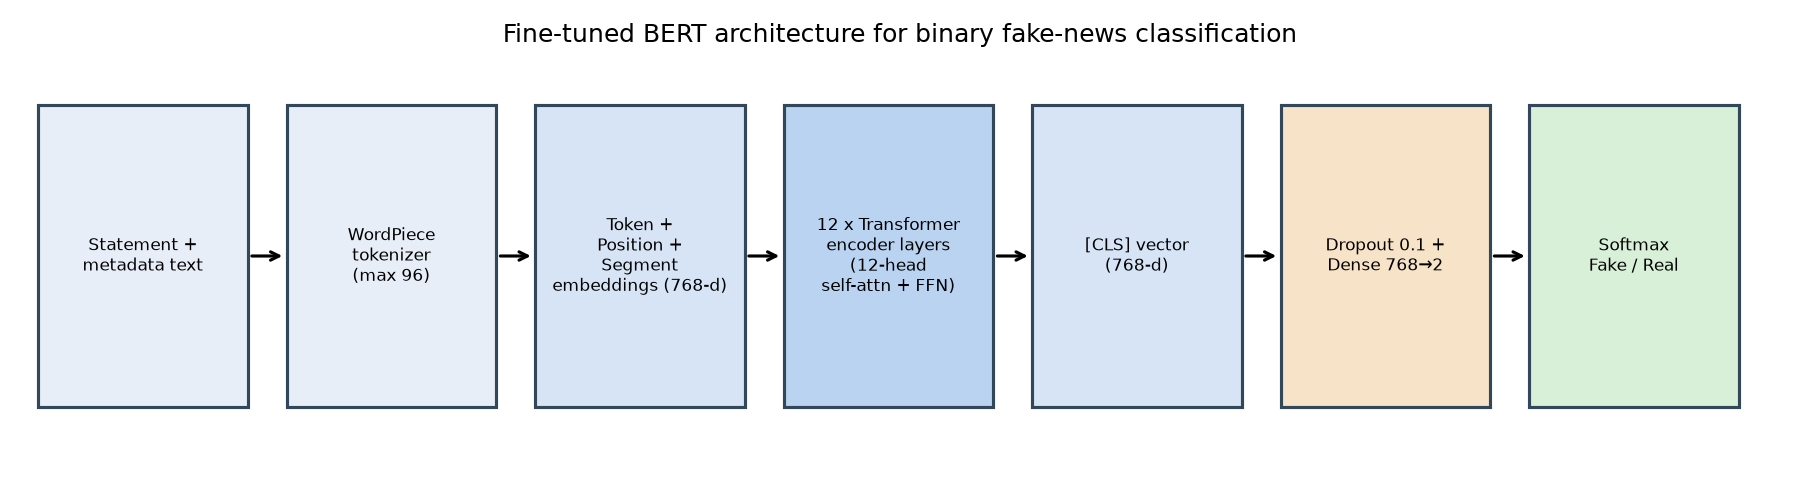

In [6]:
# Architecture diagram
fig, ax = plt.subplots(figsize=(12, 3.2)); ax.axis("off")
boxes = ["Statement +\nmetadata text", "WordPiece\ntokenizer\n(max 96)", "Token +\nPosition +\nSegment\nembeddings (768-d)",
         "12 x Transformer\nencoder layers\n(12-head\nself-attn + FFN)", "[CLS] vector\n(768-d)", "Dropout 0.1 +\nDense 768→2", "Softmax\nFake / Real"]
colors = ["#e8eef7", "#e8eef7", "#d6e4f5", "#b9d3f0", "#d6e4f5", "#f7e3c8", "#d8f0d8"]
w, gap = 1.35, 0.25
for i, (b, c) in enumerate(zip(boxes, colors)):
    x = i * (w + gap)
    ax.add_patch(plt.Rectangle((x, 0.2), w, 1.2, fc=c, ec="#33475b", lw=1.5))
    ax.text(x + w / 2, 0.8, b, ha="center", va="center", fontsize=8)
    if i < len(boxes) - 1:
        ax.annotate("", xy=(x + w + gap, 0.8), xytext=(x + w, 0.8), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.set_xlim(-0.1, len(boxes) * (w + gap)); ax.set_ylim(0, 1.6)
ax.set_title("Fine-tuned BERT architecture for binary fake-news classification")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/architecture.png", dpi=150); plt.show()

## 5. Training (fine-tuning)
Class-weighted cross-entropy (to counter the mild imbalance), AdamW (lr 2e-5, weight decay 0.01),
linear warm-up (10%) then decay, gradient clipping 1.0, 3 epochs. The checkpoint with the best
validation macro-F1 is kept.

In [7]:
counts = np.bincount(train_df["y"]); cw = torch.tensor(len(train_df) / (2 * counts), dtype=torch.float).to(DEVICE)
loss_fn = torch.nn.CrossEntropyLoss(weight=cw)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
steps = len(train_dl) * EPOCHS
sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)

@torch.no_grad()
def evaluate(dl):
    model.eval(); losses, probs, ys = [], [], []
    for x, y in dl:
        x = {k: v.to(DEVICE) for k, v in x.items()}; y = y.to(DEVICE)
        logits = model(**x).logits
        losses.append(loss_fn(logits, y).item() * len(y))
        probs.append(torch.softmax(logits, -1)[:, 1].cpu()); ys.append(y.cpu())
    p, y = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    pred = (p >= 0.5).astype(int)
    return dict(loss=sum(losses) / len(y), acc=accuracy_score(y, pred), f1=f1_score(y, pred, average="macro")), p, y

hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_f1"]}
best_f1, t0 = -1, time.time()
for ep in range(1, EPOCHS + 1):
    model.train(); tl, tc, tn = 0.0, 0, 0
    for i, (x, y) in enumerate(train_dl):
        x = {k: v.to(DEVICE) for k, v in x.items()}; y = y.to(DEVICE)
        logits = model(**x).logits; loss = loss_fn(logits, y)
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
        tl += loss.item() * len(y); tc += (logits.argmax(-1) == y).sum().item(); tn += len(y)
        if i % 50 == 0:
            msg = f"  epoch {ep} step {i}/{len(train_dl)} loss {loss.item():.4f} | {time.time()-t0:.0f}s"
            print(msg); open(f"{OUT_DIR}/train_log.txt", "a").write(msg + "\n")
    vm, _, _ = evaluate(val_dl)
    hist["train_loss"].append(tl / tn); hist["train_acc"].append(tc / tn)
    hist["val_loss"].append(vm["loss"]); hist["val_acc"].append(vm["acc"]); hist["val_f1"].append(vm["f1"])
    open(f"{OUT_DIR}/train_log.txt", "a").write(f"EPOCH {ep} val_acc={vm['acc']:.4f} val_f1={vm['f1']:.4f}\n")
    print(f"Epoch {ep}: train_loss={tl/tn:.4f} train_acc={tc/tn:.4f} | val_loss={vm['loss']:.4f} val_acc={vm['acc']:.4f} val_macroF1={vm['f1']:.4f} | {time.time()-t0:.0f}s")
    if vm["f1"] > best_f1:
        best_f1 = vm["f1"]; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
model.load_state_dict(best_state)
json.dump(hist, open(f"{OUT_DIR}/history.json", "w"), indent=2)

  epoch 1 step 0/642 loss 0.6982 | 4s


  epoch 1 step 50/642 loss 0.7106 | 77s


  epoch 1 step 100/642 loss 0.7211 | 159s


  epoch 1 step 150/642 loss 0.6055 | 238s


  epoch 1 step 200/642 loss 0.6743 | 325s


  epoch 1 step 250/642 loss 0.7498 | 405s


... (32 outputs left out)

  epoch 3 step 500/642 loss 0.6954 | 2723s


  epoch 3 step 550/642 loss 0.4575 | 2794s


  epoch 3 step 600/642 loss 0.4638 | 2876s


Epoch 3: train_loss=0.4903 train_acc=0.7705 | val_loss=0.6787 val_acc=0.6526 val_macroF1=0.6505 | 2981s


## 6. Training and validation curves

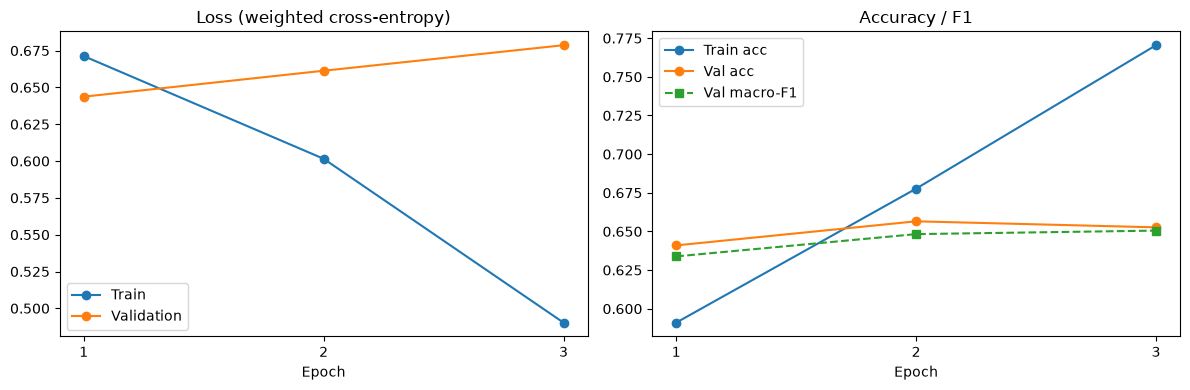

In [8]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, hist["train_loss"], "o-", label="Train"); ax[0].plot(ep, hist["val_loss"], "o-", label="Validation")
ax[0].set_title("Loss (weighted cross-entropy)"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].set_xticks(list(ep))
ax[1].plot(ep, hist["train_acc"], "o-", label="Train acc"); ax[1].plot(ep, hist["val_acc"], "o-", label="Val acc")
ax[1].plot(ep, hist["val_f1"], "s--", label="Val macro-F1")
ax[1].set_title("Accuracy / F1"); ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].set_xticks(list(ep))
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/training_curves.png", dpi=150); plt.show()

## 7. Final test evaluation

              precision    recall  f1-score   support

        Fake     0.6148    0.5683    0.5907       556
        Real     0.6879    0.7276    0.7072       727

    accuracy                         0.6586      1283
   macro avg     0.6513    0.6480    0.6489      1283
weighted avg     0.6562    0.6586    0.6567      1283



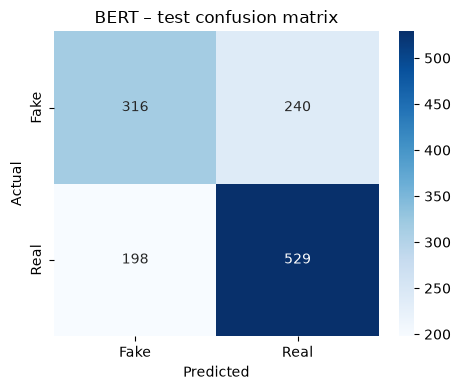

In [9]:
def metrics(y, pred, prob=None):
    m = dict(accuracy=accuracy_score(y, pred), precision_macro=precision_score(y, pred, average="macro"),
             recall_macro=recall_score(y, pred, average="macro"), f1_macro=f1_score(y, pred, average="macro"))
    if prob is not None: m["roc_auc"] = roc_auc_score(y, prob)
    return {k: round(float(v), 4) for k, v in m.items()}

_, test_prob, y_test = evaluate(test_dl)
bert_pred = (test_prob >= 0.5).astype(int)
results = {"BERT (fine-tuned)": metrics(y_test, bert_pred, test_prob)}
print(classification_report(y_test, bert_pred, target_names=CLASS_NAMES, digits=4))
cm = confusion_matrix(y_test, bert_pred)
plt.figure(figsize=(4.8, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("BERT – test confusion matrix")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=150); plt.show()

## 8. Baseline comparison
* **Majority class** – always predicts the most frequent training label.
* **TF-IDF + Logistic Regression** – word 1–2-grams (max 20k features) on the same input text, class-balanced.

/Users/anweshamulge/Downloads/FakeNews_BERT_23FE10ITE00008/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


                   accuracy  precision_macro  recall_macro  f1_macro  roc_auc
BERT (fine-tuned)    0.6586           0.6513        0.6480    0.6489   0.7054
Majority class       0.5666           0.2833        0.5000    0.3617      NaN
TF-IDF + LogReg      0.6524           0.6462        0.6463    0.6462   0.7091


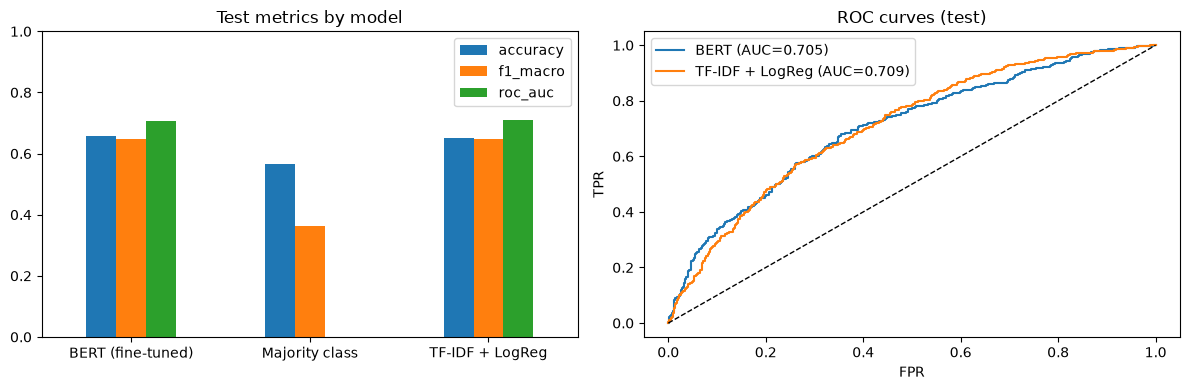

In [10]:
dummy = DummyClassifier(strategy="most_frequent").fit(train_df["text"], train_df["y"])
results["Majority class"] = metrics(y_test, dummy.predict(test_df["text"]))
tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=20000, sublinear_tf=True, min_df=2)
Xtr, Xte = tfidf.fit_transform(train_df["text"]), tfidf.transform(test_df["text"])
lr = LogisticRegression(max_iter=2000, class_weight="balanced", C=1.0).fit(Xtr, train_df["y"])
lr_prob = lr.predict_proba(Xte)[:, 1]
results["TF-IDF + LogReg"] = metrics(y_test, (lr_prob >= 0.5).astype(int), lr_prob)
res_df = pd.DataFrame(results).T[["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc"]]
print(res_df.to_string()); res_df.to_csv(f"{OUT_DIR}/results.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
res_df[["accuracy", "f1_macro", "roc_auc"]].plot.bar(ax=ax[0], rot=0); ax[0].set_ylim(0, 1); ax[0].set_title("Test metrics by model")
for name, p in [("BERT", test_prob), ("TF-IDF + LogReg", lr_prob)]:
    fpr, tpr, _ = roc_curve(y_test, p); ax[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1); ax[1].set_xlabel("FPR"); ax[1].set_ylabel("TPR"); ax[1].set_title("ROC curves (test)"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/baseline_comparison.png", dpi=150); plt.show()

## 9. Error analysis by original 6-way label and sample predictions

In [11]:
test_df["pred"] = bert_pred; test_df["p_real"] = test_prob
acc_by = test_df.assign(correct=test_df["pred"] == test_df["y"]).groupby("label")["correct"].mean().reindex(order)
print("Accuracy by original label:\n", acc_by.round(3).to_string())
acc_by.to_csv(f"{OUT_DIR}/acc_by_label.csv")
samples = test_df.sample(6, random_state=1)[["statement", "label", "y", "pred", "p_real"]]
samples.to_csv(f"{OUT_DIR}/sample_predictions.csv", index=False)
samples

Accuracy by original label:
 label
pants-fire     0.750
false          0.556
barely-true    0.505
half-true      0.629
mostly-true    0.783
true           0.787


,statement,label,y,pred,p_real
133,Says state Sen. Sheila Harsdorf wants to elimi...,pants-fire,0,0,0.116444
349,"As a prosecutor, Wisconsin Supreme Court Justi...",barely-true,0,0,0.308020
1036,Says Houstons 18th congressional district has ...,false,0,1,0.727131
268,"About 106,000 soldiers had a prescription of t...",true,1,1,0.883030
899,Says shes never said dont build Texas 45 South...,half-true,1,0,0.355158
60,"If the sequester hits, federal prosecutors wil...",barely-true,0,0,0.242051


In [12]:
def predict(statement, subject="unknown", speaker="unknown", party="unknown", context="unknown"):
    t = f"{statement} [SEP] subject: {subject} ; speaker: {speaker} ; party: {party} ; context: {context}"
    x = {k: v.to(DEVICE) for k, v in tokenizer(t, return_tensors="pt", truncation=True, max_length=MAX_LEN).items()}
    model.eval()
    with torch.no_grad(): p = torch.softmax(model(**x).logits, -1)[0, 1].item()
    return {"label": CLASS_NAMES[int(p >= 0.5)], "p_real": round(p, 3)}
print(predict("The unemployment rate has dropped to its lowest level in decades.", "economy,jobs", "unknown", "democrat", "a speech"))
json.dump({"results": results, "acc_by_label": acc_by.round(4).to_dict(), "confusion_matrix": cm.tolist(),
           "params_total": n_total, "best_val_f1": best_f1, "train_minutes": round((time.time() - t0) / 60, 1),
           "device": DEVICE}, open(f"{OUT_DIR}/metrics.json", "w"), indent=2)

{'label': 'Real', 'p_real': 0.917}
